In [1]:
import pandas as pd
import re
import html

SEED = 42                                      # same seed gives the same sample

base = "https://huggingface.co/datasets/drelhaj/AraFinNews/resolve/refs%2Fconvert%2Fparquet/default/"
train = pd.read_parquet(base + "train/0000.parquet")
validation = pd.read_parquet(base + "validation/0000.parquet")
test = pd.read_parquet(base + "test/0000.parquet")

print("Train rows:", len(train))
print("Validation rows:", len(validation))
print("Test rows:", len(test))


Train rows: 340024
Validation rows: 42502
Test rows: 42504


In [2]:
# 3 Arabic Preprocessing
for name, data in [("Train", train), ("Validation", validation), ("Test", test)]:
    print(name)
    print("Missing values:")
    print(data[["article", "title"]].isna().sum())
    print("Duplicate pairs:", data.dropna(subset=["article", "title"]).duplicated(["article", "title"]).sum())
    print()

def remove_invalid(data):
    data = data.dropna(subset=["article", "title"])           # remove missing text
    data = data[data["article"].str.strip() != ""]            # remove blank articles
    data = data[data["title"].str.strip() != ""]              # remove blank titles
    data = data.drop_duplicates(subset=["article", "title"]) # keep one copy of each pair
    return data

train = remove_invalid(train)
validation = remove_invalid(validation)
test = remove_invalid(test)


Train
Missing values:
article    170012
title      170012
dtype: int64
Duplicate pairs: 23

Validation
Missing values:
article    21251
title      21251
dtype: int64
Duplicate pairs: 1

Test
Missing values:
article    21252
title      21252
dtype: int64
Duplicate pairs: 0



In [3]:
# 3 Arabic Preprocessing
def clean_arabic(text):
    text = html.unescape(text)                             # convert &quot; to a quotation mark
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)   # remove URLs
    text = re.sub(r"<[^>]+>", " ", text)                    # remove HTML tags
    text = re.sub(r"[ؐ-ًؚ-ٰٟۖ-ۭ]", "", text)  # remove Arabic marks
    text = text.replace("ـ", "")                           # remove Tatweel
    text = re.sub("[أإآٱ]", "ا", text)                       # unify alef forms
    text = re.sub(r"\s+", " ", text).strip()                # remove extra spaces
    return text


In [4]:
## 4 Select the Required Records

def select_records(data, number, used_articles):
    data = data.sample(frac=1, random_state=SEED)            # shuffle reproducibly
    records = []
    for _, row in data.iterrows():
        article = clean_arabic(row["article"])
        title = clean_arabic(row["title"])
        if article == "" or title == "":                   # skip empty cleaned text
            continue
        if article in used_articles:                       # skip an already selected article
            continue
        used_articles.add(article)
        records.append({"article": row["article"], "title": row["title"],
                        "clean_article": article, "clean_title": title})
        if len(records) == number:
            break
    if len(records) != number:
        raise ValueError("Not enough valid records")
    return pd.DataFrame(records)

used_articles = set()                                      # track selected articles across splits
train = select_records(train, 5000, used_articles)
validation = select_records(validation, 1000, used_articles)
test = select_records(test, 1000, used_articles)

print("Selected train:", len(train))
print("Selected validation:", len(validation))
print("Selected test:", len(test))

for name, data in [("Train", train), ("Validation", validation), ("Test", test)]:
    print("\n" + name)
    print("Missing values:")
    print(data[["article", "title"]].isna().sum())
    print("Duplicate pairs:", data.duplicated(["article", "title"]).sum())


Selected train: 5000
Selected validation: 1000
Selected test: 1000

Train
Missing values:
article    0
title      0
dtype: int64
Duplicate pairs: 0

Validation
Missing values:
article    0
title      0
dtype: int64
Duplicate pairs: 0

Test
Missing values:
article    0
title      0
dtype: int64
Duplicate pairs: 0


In [5]:
## 5 Five Article–Headline Examples
display(train[["article", "title"]].head(5))       # show five original pairs


,article,title
0,"ترسل الولايات المتحدة الجمعة حوالى 1,9 مليون جرعة لقاح ضد كوفيد-19 إلى زامبيا والكونغو-برازافيل وناميبيا وموزمبيق ومملكة اسواتيني الصغيرة، بحسب ما أعلن مسؤول في البيت الأبيض طلب عدم الكشف عن اسمه. وستحصل زامبيا على 672000 جرعة من لقاح جونسون اند جونسون، والكونغو على 168000 جرعة من اللقاح نفسه، وستحصل ناميبيا كذلك على 168000 جرعة وموزمبيق على 840000 جرعة، بحسب المصدر. وستحصل اسواتيني من جهتها على 50310 جرعات من لقاح فايزر. وتُمنح هذه الهبات بواسطة آلية كوفاكس العالمية لتوزيع اللقاحات، وعبر نظام مماثل وضعه الاتحاد الافريقي للقاح جونسون اند جونسون. وأوضح البيت الأبيض أنّ هذه الهبات تُمنح بدون شروط، في إشارة إلى أن الوضع ليس كذلك بالنسبة لكل المانحين الكبار، وأولهم الصين. ويشدد الرئيس جو بايدن على أنه يريد أن يجعل من الولايات المتحدة ترسانة اللقاحات في العالم. وتعهد منح أكثر من 1,1 مليار جرعة.",واشنطن تعلن إرسال لقاحات إلى دول إفريقية
1,تراجعت أرباح مجموعة سيتي غروب في الربع الثالث من العام الجاري بنسبة 25 بالمئة على أساس سنوي، بسبب هبوط عوائد المنتجات الاستثمارية وتراجع الخدمات المصرفية. وفي الربع المنتهي في 30 سبتمبر الماضي، بلغت أرباح البنك الاستثماري 3.5 مليار دولار، بحسب تقرير للبنك، مقابل أرباح بقيمة 4.6 مليار دولار في الربع الثالث من عام 2021. وبرغم التراجع في الأرباح، أعلن البنك، الجمعة، ارتفاع الإيرادات بأكثر من التوقعات وبنسبة 6 بالمئة على أساس سنوي، لتصل إلى 18.5 مليار دولار، مقابل توقعات بقيمة 18.25 مليار دولار بحسب بيانات ريفينيتيف. وكانت إيرادات البنك قد بلغت 17.4 مليار دولار في الربع الثالث من عام 2021. وأرجع البنك التراجع في الأرباح بشكل أساسي إلى ارتفاع تكلفة الائتمان الناتجة عن نمو القروض، وارتفاع مصاريف التشغيل. وقالت جين فريسر، المديرة التنفيذية لمجموعة سيتي غروب إن البنك يركز بشكل مكثف على دعم العملاء وتنفيذ استراتيجيته المحددة، مؤكدة تحقيق تقدم جيد في العديد من محركات الأعمال الأساسية على الرغم من أوضاع البيئة الاقتصادية الكلية المعقدة. وأضافت فريسر أن البنك يعمل على مواصلة تقليص أعماله في روسيا، مؤكدة أن معظم العمليات البنكية فيروسياستنتهي خلال الربع القادم، وأن البنك يعتزم إنهاء أعماله في البلاد بشكل كلي.,أرباح &quot;سيتي غروب&quot; تتراجع 25 بالمئة رغم ارتفاع الإيرادات
2,تراجعت الأسهم الصينية بنهاية تداولات اليوم الثلاثاء، لتنهي رحلة من المكاسب دامت لعدة جلسات، بفعل مخاوف التأثير السلبي المحتمل لعودة الطروحات العامة في السوق. وحولت الأسهم اتجاهها من المكاسب للهبوط خلال التداولات، بفعل تراجع أسهم قطاع التكنولوجيا والشركات الصغيرة، مع التكهنات بشأن احتمالية بيع بعض المستثمرين للأسهم من أجل الدخول في عمليات اكتتابات جديدة. وكانت السلطات الصينية قد أعلنت إنهاء الحظر المفروض على طرح اكتتابات جديدة في السوق، بعد التعافي النسبي الذي سجلته الأسهم في الفترة الأخيرة. وهبط مؤشر شنغهاي المركب بنسبة 0.1% ليصل إلى 3604 نقاط عند الإغلاق، بعد مكاسب وصلت إلى 2% أثناء الجلسة.,الأسهم الصينية تتحول من المكاسب للهبوط بفعل مخاوف عودة الاكتتابات
3,قال وزير الطاقة الروسي ألكسندر نوفاك اليوم الأربعاء إنه قلق بشأن تباطؤ الاقتصاد العالمي وإن تحالف أوبك+ سيبحث غدا الخميس تباطؤ الطلب على النفط. وأضاف أنه لا توجد مقترحات جديدة لتغيير أحجام إنتاج النفط في إطار الاتفاق العالمي، لكن المجموعة قد تناقش معايير قياس جديدة لمراقبة الاتفاق.,&quot;نوفاك&quot;: أوبك+ ستبحث تباطؤ الطلب العالمي على النفط
4,نفى وزير الصحة البريطاني ساجد جاويد اتجاه المملكة المتحدة إلى إعادة تطبيق القيود المرتبطة بالإغلاق مرة أخرى، وفقًا لشبكة سكاي نيوز. وأكد جاويد، الإثنين، أن الأولوية الأهم في الوقت الراهن هي عودة الحياة إلى الوضع الطبيعي في أسرع وقت ممكن. ومن المقرر أن يدلي جاويد ببيان أمام مجلس العموم البريطاني في وقت لاحق اليوم.,وزير الصحة البريطاني ينفي العودة لتطبيق إجراءات الإغلاق


In [6]:
# Average Word Counts
for name, data in [("Train", train), ("Validation", validation), ("Test", test)]:
    article_lengths = data["article"].str.split().str.len()  # count article words
    title_lengths = data["title"].str.split().str.len()      # count title words

    print(name)
    print("Average article words:", round(article_lengths.mean(), 2))
    print("Average title words:", round(title_lengths.mean(), 2))
    print()

Train
Average article words: 181.57
Average title words: 10.32

Validation
Average article words: 182.45
Average title words: 10.25

Test
Average article words: 193.7
Average title words: 10.29



In [7]:
# Five Before/After Examples
display(train[["article", "clean_article"]].head(5))       # article before and after cleaning
display(train[["title", "clean_title"]].head(5))           # headline before and after cleaning


,article,clean_article
0,"ترسل الولايات المتحدة الجمعة حوالى 1,9 مليون جرعة لقاح ضد كوفيد-19 إلى زامبيا والكونغو-برازافيل وناميبيا وموزمبيق ومملكة اسواتيني الصغيرة، بحسب ما أعلن مسؤول في البيت الأبيض طلب عدم الكشف عن اسمه. وستحصل زامبيا على 672000 جرعة من لقاح جونسون اند جونسون، والكونغو على 168000 جرعة من اللقاح نفسه، وستحصل ناميبيا كذلك على 168000 جرعة وموزمبيق على 840000 جرعة، بحسب المصدر. وستحصل اسواتيني من جهتها على 50310 جرعات من لقاح فايزر. وتُمنح هذه الهبات بواسطة آلية كوفاكس العالمية لتوزيع اللقاحات، وعبر نظام مماثل وضعه الاتحاد الافريقي للقاح جونسون اند جونسون. وأوضح البيت الأبيض أنّ هذه الهبات تُمنح بدون شروط، في إشارة إلى أن الوضع ليس كذلك بالنسبة لكل المانحين الكبار، وأولهم الصين. ويشدد الرئيس جو بايدن على أنه يريد أن يجعل من الولايات المتحدة ترسانة اللقاحات في العالم. وتعهد منح أكثر من 1,1 مليار جرعة.","ترسل الولايات المتحدة الجمعة حوالى 1,9 مليون جرعة لقاح ضد كوفيد-19 الى زامبيا والكونغو-برازافيل وناميبيا وموزمبيق ومملكة اسواتيني الصغيرة، بحسب ما اعلن مسؤول في البيت الابيض طلب عدم الكشف عن اسمه. وستحصل زامبيا على 672000 جرعة من لقاح جونسون اند جونسون، والكونغو على 168000 جرعة من اللقاح نفسه، وستحصل ناميبيا كذلك على 168000 جرعة وموزمبيق على 840000 جرعة، بحسب المصدر. وستحصل اسواتيني من جهتها على 50310 جرعات من لقاح فايزر. وتمنح هذه الهبات بواسطة الية كوفاكس العالمية لتوزيع اللقاحات، وعبر نظام مماثل وضعه الاتحاد الافريقي للقاح جونسون اند جونسون. واوضح البيت الابيض ان هذه الهبات تمنح بدون شروط، في اشارة الى ان الوضع ليس كذلك بالنسبة لكل المانحين الكبار، واولهم الصين. ويشدد الرئيس جو بايدن على انه يريد ان يجعل من الولايات المتحدة ترسانة اللقاحات في العالم. وتعهد منح اكثر من 1,1 مليار جرعة."
1,تراجعت أرباح مجموعة سيتي غروب في الربع الثالث من العام الجاري بنسبة 25 بالمئة على أساس سنوي، بسبب هبوط عوائد المنتجات الاستثمارية وتراجع الخدمات المصرفية. وفي الربع المنتهي في 30 سبتمبر الماضي، بلغت أرباح البنك الاستثماري 3.5 مليار دولار، بحسب تقرير للبنك، مقابل أرباح بقيمة 4.6 مليار دولار في الربع الثالث من عام 2021. وبرغم التراجع في الأرباح، أعلن البنك، الجمعة، ارتفاع الإيرادات بأكثر من التوقعات وبنسبة 6 بالمئة على أساس سنوي، لتصل إلى 18.5 مليار دولار، مقابل توقعات بقيمة 18.25 مليار دولار بحسب بيانات ريفينيتيف. وكانت إيرادات البنك قد بلغت 17.4 مليار دولار في الربع الثالث من عام 2021. وأرجع البنك التراجع في الأرباح بشكل أساسي إلى ارتفاع تكلفة الائتمان الناتجة عن نمو القروض، وارتفاع مصاريف التشغيل. وقالت جين فريسر، المديرة التنفيذية لمجموعة سيتي غروب إن البنك يركز بشكل مكثف على دعم العملاء وتنفيذ استراتيجيته المحددة، مؤكدة تحقيق تقدم جيد في العديد من محركات الأعمال الأساسية على الرغم من أوضاع البيئة الاقتصادية الكلية المعقدة. وأضافت فريسر أن البنك يعمل على مواصلة تقليص أعماله في روسيا، مؤكدة أن معظم العمليات البنكية فيروسياستنتهي خلال الربع القادم، وأن البنك يعتزم إنهاء أعماله في البلاد بشكل كلي.,تراجعت ارباح مجموعة سيتي غروب في الربع الثالث من العام الجاري بنسبة 25 بالمئة على اساس سنوي، بسبب هبوط عوائد المنتجات الاستثمارية وتراجع الخدمات المصرفية. وفي الربع المنتهي في 30 سبتمبر الماضي، بلغت ارباح البنك الاستثماري 3.5 مليار دولار، بحسب تقرير للبنك، مقابل ارباح بقيمة 4.6 مليار دولار في الربع الثالث من عام 2021. وبرغم التراجع في الارباح، اعلن البنك، الجمعة، ارتفاع الايرادات باكثر من التوقعات وبنسبة 6 بالمئة على اساس سنوي، لتصل الى 18.5 مليار دولار، مقابل توقعات بقيمة 18.25 مليار دولار بحسب بيانات ريفينيتيف. وكانت ايرادات البنك قد بلغت 17.4 مليار دولار في الربع الثالث من عام 2021. وارجع البنك التراجع في الارباح بشكل اساسي الى ارتفاع تكلفة الائتمان الناتجة عن نمو القروض، وارتفاع مصاريف التشغيل. وقالت جين فريسر، المديرة التنفيذية لمجموعة سيتي غروب ان البنك يركز بشكل مكثف على دعم العملاء وتنفيذ استراتيجيته المحددة، مؤكدة تحقيق تقدم جيد في العديد من محركات الاعمال الاساسية على الرغم من اوضاع البيئة الاقتصادية الكلية المعقدة. واضافت فريسر ان البنك يعمل على مواصلة تقليص اعماله في روسيا، مؤكدة ان معظم العمليات البنكية فيروسياستنتهي خلال الربع القادم، وان البنك يعتزم انهاء اعماله في البلاد بشكل كلي.
2,تراجعت الأسهم الصينية بنهاية تداولات اليوم الثلاثاء، لتنهي رحلة من المكاسب دامت لعدة جلسات، بفعل مخاوف التأثير السلبي المحتمل لعودة الطروحات

,title,clean_title
0,واشنطن تعلن إرسال لقاحات إلى دول إفريقية,واشنطن تعلن ارسال لقاحات الى دول افريقية
1,أرباح &quot;سيتي غروب&quot; تتراجع 25 بالمئة رغم ارتفاع الإيرادات,"ارباح ""سيتي غروب"" تتراجع 25 بالمئة رغم ارتفاع الايرادات"
2,الأسهم الصينية تتحول من المكاسب للهبوط بفعل مخاوف عودة الاكتتابات,الاسهم الصينية تتحول من المكاسب للهبوط بفعل مخاوف عودة الاكتتابات
3,&quot;نوفاك&quot;: أوبك+ ستبحث تباطؤ الطلب العالمي على النفط,"""نوفاك"": اوبك+ ستبحث تباطؤ الطلب العالمي على النفط"
4,وزير الصحة البريطاني ينفي العودة لتطبيق إجراءات الإغلاق,وزير الصحة البريطاني ينفي العودة لتطبيق اجراءات الاغلاق


In [8]:
from collections import Counter
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [9]:
PAD_TOKEN = "[PAD]"
UNK_TOKEN = "[UNK]"
SOS_TOKEN = "[SOS]"
EOS_TOKEN = "[EOS]"

MAX_ARTICLE_LEN = 80
MAX_TITLE_LEN = 20

In [10]:
def tokenize_text(text):
    return text.split()

In [11]:
word_counter = Counter()

for article in train["clean_article"]:
    word_counter.update(tokenize_text(article))

for title in train["clean_title"]:
    word_counter.update(tokenize_text(title))
    special_tokens = [
    PAD_TOKEN,
    UNK_TOKEN,
    SOS_TOKEN,
    EOS_TOKEN
]

word_to_id = {}

for token in special_tokens:
    word_to_id[token] = len(word_to_id)
for word, count in word_counter.items():
    if word not in word_to_id:
        word_to_id[word] = len(word_to_id)
id_to_word = {
    idx: word for word, idx in word_to_id.items()
}

VOCAB_SIZE = len(word_to_id)

print("Vocabulary size:", VOCAB_SIZE)
print("PAD ID:", word_to_id[PAD_TOKEN])
print("UNK ID:", word_to_id[UNK_TOKEN])
print("SOS ID:", word_to_id[SOS_TOKEN])
print("EOS ID:", word_to_id[EOS_TOKEN])

Vocabulary size: 92121
PAD ID: 0
UNK ID: 1
SOS ID: 2
EOS ID: 3


#**Convert Text into Integer Sequences**

In [12]:
def text_to_sequence(text):
    tokens = tokenize_text(text)

    sequence = [
        word_to_id.get(word, word_to_id[UNK_TOKEN])
        for word in tokens
    ]

    return sequence
sample_text = "الذكاء الاصطناعي يساعد المجتمع"

sample_sequence = text_to_sequence(sample_text)

print("Text:", sample_text)
print("Sequence:", sample_sequence)

Text: الذكاء الاصطناعي يساعد المجتمع
Sequence: [3110, 3111, 14168, 12755]


#**Encode Articles and Titles**

In [13]:
def encode_article(text):
    sequence = text_to_sequence(text)

    return sequence[:MAX_ARTICLE_LEN]
def encode_title(text):
    sequence = text_to_sequence(text)

    sequence = sequence[:MAX_TITLE_LEN - 2]

    sequence = (
        [word_to_id[SOS_TOKEN]]
        + sequence
        + [word_to_id[EOS_TOKEN]]
    )

    return sequence

#**Apply Encoding**

In [14]:
train_articles = [
    encode_article(text)
    for text in train["clean_article"]
]

train_titles = [
    encode_title(text)
    for text in train["clean_title"]
]

validation_articles = [
    encode_article(text)
    for text in validation["clean_article"]
]

validation_titles = [
    encode_title(text)
    for text in validation["clean_title"]
]

test_articles = [
    encode_article(text)
    for text in test["clean_article"]
]

test_titles = [
    encode_title(text)
    for text in test["clean_title"]
]

#**Padding & Truncation**

In [15]:
train_encoder_input = pad_sequences(
    train_articles,
    maxlen=MAX_ARTICLE_LEN,
    padding="post",
    truncating="post",
    value=word_to_id[PAD_TOKEN]
)

validation_encoder_input = pad_sequences(
    validation_articles,
    maxlen=MAX_ARTICLE_LEN,
    padding="post",
    truncating="post",
    value=word_to_id[PAD_TOKEN]
)

test_encoder_input = pad_sequences(
    test_articles,
    maxlen=MAX_ARTICLE_LEN,
    padding="post",
    truncating="post",
    value=word_to_id[PAD_TOKEN]
)
#for title
train_title_padded = pad_sequences(
    train_titles,
    maxlen=MAX_TITLE_LEN,
    padding="post",
    truncating="post",
    value=word_to_id[PAD_TOKEN]
)

validation_title_padded = pad_sequences(
    validation_titles,
    maxlen=MAX_TITLE_LEN,
    padding="post",
    truncating="post",
    value=word_to_id[PAD_TOKEN]
)

test_title_padded = pad_sequences(
    test_titles,
    maxlen=MAX_TITLE_LEN,
    padding="post",
    truncating="post",
    value=word_to_id[PAD_TOKEN]
)

#**Decoder Inputs & Shifted Targets**

In [16]:
train_decoder_input = train_title_padded[:, :-1]
train_decoder_target = train_title_padded[:, 1:]

validation_decoder_input = validation_title_padded[:, :-1]
validation_decoder_target = validation_title_padded[:, 1:]

test_decoder_input = test_title_padded[:, :-1]
test_decoder_target = test_title_padded[:, 1:]
print("Vocabulary size:", VOCAB_SIZE)

print("\nEncoder Input Shape:")
print("Train:", train_encoder_input.shape)
print("Validation:", validation_encoder_input.shape)
print("Test:", test_encoder_input.shape)

print("\nDecoder Input Shape:")
print("Train:", train_decoder_input.shape)
print("Validation:", validation_decoder_input.shape)
print("Test:", test_decoder_input.shape)

print("\nDecoder Target Shape:")
print("Train:", train_decoder_target.shape)
print("Validation:", validation_decoder_target.shape)
print("Test:", test_decoder_target.shape)

Vocabulary size: 92121

Encoder Input Shape:
Train: (5000, 80)
Validation: (1000, 80)
Test: (1000, 80)

Decoder Input Shape:
Train: (5000, 19)
Validation: (1000, 19)
Test: (1000, 19)

Decoder Target Shape:
Train: (5000, 19)
Validation: (1000, 19)
Test: (1000, 19)


In [17]:
#for Display a Sample
sample_index = 0

print("Original Article:")
print(train["clean_article"].iloc[sample_index])

print("\nOriginal Title:")
print(train["clean_title"].iloc[sample_index])

print("\nArticle Sequence:")
print(train_encoder_input[sample_index])

print("\nDecoder Input:")
print(train_decoder_input[sample_index])

print("\nDecoder Target:")
print(train_decoder_target[sample_index])

Original Article:
ترسل الولايات المتحدة الجمعة حوالى 1,9 مليون جرعة لقاح ضد كوفيد-19 الى زامبيا والكونغو-برازافيل وناميبيا وموزمبيق ومملكة اسواتيني الصغيرة، بحسب ما اعلن مسؤول في البيت الابيض طلب عدم الكشف عن اسمه. وستحصل زامبيا على 672000 جرعة من لقاح جونسون اند جونسون، والكونغو على 168000 جرعة من اللقاح نفسه، وستحصل ناميبيا كذلك على 168000 جرعة وموزمبيق على 840000 جرعة، بحسب المصدر. وستحصل اسواتيني من جهتها على 50310 جرعات من لقاح فايزر. وتمنح هذه الهبات بواسطة الية كوفاكس العالمية لتوزيع اللقاحات، وعبر نظام مماثل وضعه الاتحاد الافريقي للقاح جونسون اند جونسون. واوضح البيت الابيض ان هذه الهبات تمنح بدون شروط، في اشارة الى ان الوضع ليس كذلك بالنسبة لكل المانحين الكبار، واولهم الصين. ويشدد الرئيس جو بايدن على انه يريد ان يجعل من الولايات المتحدة ترسانة اللقاحات في العالم. وتعهد منح اكثر من 1,1 مليار جرعة.

Original Title:
واشنطن تعلن ارسال لقاحات الى دول افريقية

Article Sequence:
[ 4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27
 28 29 30 31 32 33 34 35 16 36 37 

In [18]:
#Decode Sequence Back to Text
def sequence_to_text(sequence):
    words = []

    for idx in sequence:
        word = id_to_word.get(int(idx), UNK_TOKEN)

        if word == PAD_TOKEN:
            continue

        if word == SOS_TOKEN:
            continue

        if word == EOS_TOKEN:
            break

        words.append(word)

    return " ".join(words)
sample_sequence = train_encoder_input[0]

print("Decoded Article:")
print(sequence_to_text(sample_sequence))

Decoded Article:
ترسل الولايات المتحدة الجمعة حوالى 1,9 مليون جرعة لقاح ضد كوفيد-19 الى زامبيا والكونغو-برازافيل وناميبيا وموزمبيق ومملكة اسواتيني الصغيرة، بحسب ما اعلن مسؤول في البيت الابيض طلب عدم الكشف عن اسمه. وستحصل زامبيا على 672000 جرعة من لقاح جونسون اند جونسون، والكونغو على 168000 جرعة من اللقاح نفسه، وستحصل ناميبيا كذلك على 168000 جرعة وموزمبيق على 840000 جرعة، بحسب المصدر. وستحصل اسواتيني من جهتها على 50310 جرعات من لقاح فايزر. وتمنح هذه الهبات بواسطة الية كوفاكس العالمية لتوزيع اللقاحات، وعبر


#**SimpleRNN Encoder–Decoder**

In [25]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

EMBEDDING_DIM = 128
RNN_UNITS = 128
EPOCHS = 20
BATCH_SIZE = 32
DROPOUT_RATE = 0.1

tf.keras.utils.set_random_seed(SEED)

In [26]:
#Build Encoder
encoder_inputs = Input(shape=(MAX_ARTICLE_LEN,))

encoder_embedding = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=True
)

encoder_embedded = encoder_embedding(encoder_inputs)

encoder_rnn = SimpleRNN(
    RNN_UNITS,
    return_state=True,
    dropout=DROPOUT_RATE
)

encoder_outputs, encoder_state = encoder_rnn(encoder_embedded)


#Build Decoder
decoder_inputs = Input(shape=(MAX_TITLE_LEN - 1,))

decoder_embedding = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=True
)

decoder_embedded = decoder_embedding(decoder_inputs)

decoder_rnn = SimpleRNN(
    RNN_UNITS,
    return_sequences=True,
    return_state=True,
    dropout=DROPOUT_RATE
)

decoder_outputs, decoder_state = decoder_rnn(
    decoder_embedded,
    initial_state=encoder_state
)

In [27]:
#Output Layer
decoder_dense = Dense(
    VOCAB_SIZE,
    activation="softmax"
)

decoder_outputs = decoder_dense(decoder_outputs)

In [28]:
#Build and Compile Model
rnn_model = Model(
    inputs=[encoder_inputs, decoder_inputs],
    outputs=decoder_outputs
)

rnn_model.compile(
    optimizer=Adam(learning_rate=0.0005, clipnorm=1.0),
    loss="sparse_categorical_crossentropy",
    weighted_metrics=["sparse_categorical_accuracy"]
)

rnn_model.summary()

Model: "functional"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 80)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 80, 128)   │ 11,791,488 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 80)        │          0 │

In [29]:
#Prepare Sample Weights
PAD_ID = word_to_id[PAD_TOKEN]

train_sample_weights = (
    train_decoder_target != PAD_ID
).astype("float32")

validation_sample_weights = (
    validation_decoder_target != PAD_ID
).astype("float32")

In [30]:
#Train SimpleRNN Model
rnn_history = rnn_model.fit(
    [train_encoder_input, train_decoder_input],
    train_decoder_target,

    sample_weight=train_sample_weights,

    validation_data=(
        [validation_encoder_input, validation_decoder_input],
        validation_decoder_target,
        validation_sample_weights
    ),

    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

Epoch 1/20
157/157 - 72s - 456ms/step - loss: 8.2312 - sparse_categorical_accuracy: 0.0843 - val_loss: 7.4691 - val_sparse_categorical_accuracy: 0.0889
Epoch 2/20
157/157 - 64s - 409ms/step - loss: 7.0377 - sparse_categorical_accuracy: 0.0884 - val_loss: 7.3695 - val_sparse_categorical_accuracy: 0.0889
Epoch 3/20
157/157 - 69s - 438ms/step - loss: 6.8159 - sparse_categorical_accuracy: 0.0944 - val_loss: 7.2740 - val_sparse_categorical_accuracy: 0.0981
Epoch 4/20
157/157 - 68s - 432ms/step - loss: 6.6097 - sparse_categorical_accuracy: 0.1035 - val_loss: 7.1887 - val_sparse_categorical_accuracy: 0.1083
Epoch 5/20
157/157 - 67s - 429ms/step - loss: 6.4163 - sparse_categorical_accuracy: 0.1113 - val_loss: 7.1197 - val_sparse_categorical_accuracy: 0.1133
Epoch 6/20
157/157 - 66s - 423ms/step - loss: 6.2427 - sparse_categorical_accuracy: 0.1171 - val_loss: 7.0978 - val_sparse_categorical_accuracy: 0.1159
Epoch 7/20
157/157 - 68s - 432ms/step - loss: 6.0676 - sparse_categorical_accuracy: 0.12

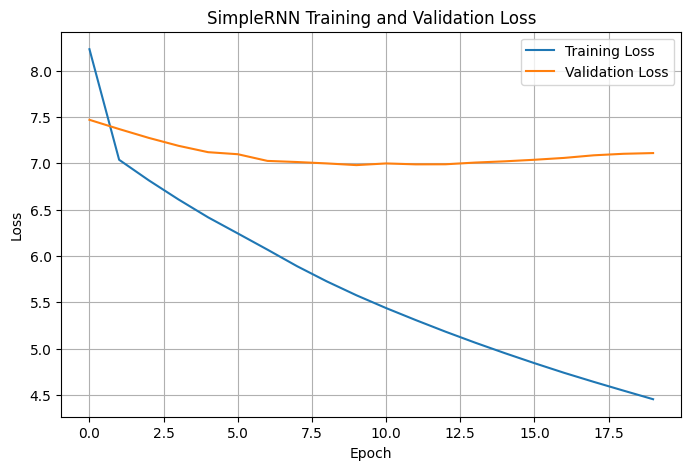

In [31]:
#Plot Training and Validation Loss
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.plot(
    rnn_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    rnn_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("SimpleRNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

In [32]:
#Build Encoder Inference Model
encoder_model = Model(
    inputs=encoder_inputs,
    outputs=encoder_state
)

#Build Decoder Inference Model
decoder_token_input = Input(shape=(1,))

decoder_state_input = Input(shape=(RNN_UNITS,))

decoder_embedded_step = decoder_embedding(decoder_token_input)

decoder_outputs_step, decoder_state_step = decoder_rnn(
    decoder_embedded_step,
    initial_state=decoder_state_input
)

decoder_probabilities = decoder_dense(decoder_outputs_step)

decoder_model = Model(
    inputs=[decoder_token_input, decoder_state_input],
    outputs=[decoder_probabilities, decoder_state_step]
)

In [33]:
#Generate Headline Function
def generate_rnn_headline(article_sequence):

    state = encoder_model.predict(
        article_sequence.reshape(1, -1),
        verbose=0
    )

    current_token = np.array([
        [word_to_id[SOS_TOKEN]]
    ])

    generated_sequence = []

    for _ in range(MAX_TITLE_LEN - 1):

        probabilities, state = decoder_model.predict(
            [current_token, state],
            verbose=0
        )

        next_token = int(
            np.argmax(probabilities[0, -1, :])
        )

        if next_token == word_to_id[EOS_TOKEN]:
            break

        if next_token == word_to_id[PAD_TOKEN]:
            break

        generated_sequence.append(next_token)

        current_token = np.array([[next_token]])

    return sequence_to_text(generated_sequence)

In [34]:
#Test SimpleRNN Generation
sample_index = 0

sample_article = test_encoder_input[sample_index]

predicted_headline = generate_rnn_headline(sample_article)

print("Original Article:")
print(test["clean_article"].iloc[sample_index])

print("\nReference Headline:")
print(test["clean_title"].iloc[sample_index])

print("\nSimpleRNN Predicted Headline:")
print(predicted_headline)

Original Article:
قال الكرملين اليوم الاربعاء انه يتعين رفع العقوبات المفروضة على روسيا حتى يتم تسليم الحبوب الروسية الى الاسواق الدولية. وافاد المتحدث باسم الكرملين دميتري بيسكوف في اتصال مع الصحفيين بانه لا توجد مناقشات فعلية جارية بشان رفع العقوبات.

Reference Headline:
الكرملين: يجب رفع العقوبات لتسليم الحبوب الروسية للاسواق

SimpleRNN Predicted Headline:
تراجع الاسهم الامريكية في بداية الجلسة مع ارتفاع الاسهم


In [35]:
#Generate 5 Sample Predictions
for i in range(5):

    predicted_headline = generate_rnn_headline(
        test_encoder_input[i]
    )

    print("=" * 80)

    print("Article:")
    print(test["clean_article"].iloc[i])

    print("\nReference Headline:")
    print(test["clean_title"].iloc[i])

    print("\nSimpleRNN Prediction:")
    print(predicted_headline)

    print("=" * 80)

Article:
قال الكرملين اليوم الاربعاء انه يتعين رفع العقوبات المفروضة على روسيا حتى يتم تسليم الحبوب الروسية الى الاسواق الدولية. وافاد المتحدث باسم الكرملين دميتري بيسكوف في اتصال مع الصحفيين بانه لا توجد مناقشات فعلية جارية بشان رفع العقوبات.

Reference Headline:
الكرملين: يجب رفع العقوبات لتسليم الحبوب الروسية للاسواق

SimpleRNN Prediction:
تراجع الاسهم الامريكية في بداية الجلسة مع ارتفاع الاسهم
Article:
وافق مجلس الشيوخ الامريكي اليوم على تمديد سقف الدين وتمويل الحكومة حتى الثامن من ديسمبر/كانون الاول المقبل. واقر المجلس ايضا مضاعفة حزمة المساعدات لضحايا الاعصار هارفي الى 15.25 مليار دولار مع اقتراب العاصفة ارما من فلوريدا. ويعود قرار مضاعفة حزمة المساعدات لضحايا الاعصار الى مجلس النواب للتصويت عليه، ووافق مجلس الشيوخ على الحزمة باغلبية كبيرة دون معارضة من اي عضو جمهوري.

Reference Headline:
مجلس الشيوخ الامريكي يقر حزمة مساعدات مضاعفة لضحايا "هارفي" وتمديد تمويل الحكومة

SimpleRNN Prediction:
وكالة: الصين تعتزم رفع الفائدة جديدة في العالم
Article:
قالت وكالة فيتش ان تجنب الاغلاق ال

# Build LSTM Encoder

In [37]:

from tensorflow.keras.layers import LSTM

# Set random seed
tf.keras.utils.set_random_seed(SEED)

# Build LSTM Encoder
encoder_inputs_lstm = Input(shape=(MAX_ARTICLE_LEN,))

encoder_embedding_lstm = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=True
)

encoder_embedded_lstm = encoder_embedding_lstm(
    encoder_inputs_lstm
)

encoder_lstm = LSTM(
    RNN_UNITS,
    return_state=True,
    dropout=DROPOUT_RATE
)

encoder_outputs_lstm, hidden_state, cell_state = encoder_lstm(
    encoder_embedded_lstm
)


# Build LSTM Decoder

In [39]:

# Build LSTM Decoder
decoder_inputs_lstm = Input(shape=(MAX_TITLE_LEN - 1,))

decoder_embedding_lstm = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=True
)

decoder_embedded_lstm = decoder_embedding_lstm(
    decoder_inputs_lstm
)

decoder_lstm = LSTM(
    RNN_UNITS,
    return_sequences=True,
    return_state=True,
    dropout=DROPOUT_RATE
)

decoder_outputs_lstm, _, _ = decoder_lstm(
    decoder_embedded_lstm,
    initial_state=[hidden_state, cell_state]
)


In [40]:

# Output Layer
decoder_dense_lstm = Dense(
    VOCAB_SIZE,
    activation="softmax"
)

decoder_outputs_lstm = decoder_dense_lstm(
    decoder_outputs_lstm
)

# Build LSTM Model
lstm_model = Model(
    inputs=[encoder_inputs_lstm, decoder_inputs_lstm],
    outputs=decoder_outputs_lstm
)

# Compile Model
lstm_model.compile(
    optimizer=Adam(learning_rate=0.0005, clipnorm=1.0),
    loss="sparse_categorical_crossentropy",
    weighted_metrics=["sparse_categorical_accuracy"]
)

lstm_model.summary()


Model: "functional"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 80)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 80, 128)   │ 11,791,488 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 80)        │          0 │

# Train LSTM Model

In [42]:

# Train LSTM Model
lstm_history = lstm_model.fit(
    [train_encoder_input, train_decoder_input],
    train_decoder_target,

    sample_weight=train_sample_weights,

    validation_data=(
        [validation_encoder_input, validation_decoder_input],
        validation_decoder_target,
        validation_sample_weights
    ),

    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)


Epoch 1/20
157/157 - 75s - 480ms/step - loss: 8.3796 - sparse_categorical_accuracy: 0.0866 - val_loss: 7.4565 - val_sparse_categorical_accuracy: 0.0889
Epoch 2/20
157/157 - 81s - 518ms/step - loss: 7.0211 - sparse_categorical_accuracy: 0.0885 - val_loss: 7.3226 - val_sparse_categorical_accuracy: 0.0899
Epoch 3/20
157/157 - 74s - 470ms/step - loss: 6.7817 - sparse_categorical_accuracy: 0.0974 - val_loss: 7.2633 - val_sparse_categorical_accuracy: 0.1062
Epoch 4/20
157/157 - 73s - 464ms/step - loss: 6.6275 - sparse_categorical_accuracy: 0.1079 - val_loss: 7.2730 - val_sparse_categorical_accuracy: 0.1063
Epoch 5/20
157/157 - 72s - 460ms/step - loss: 6.5101 - sparse_categorical_accuracy: 0.1121 - val_loss: 7.2637 - val_sparse_categorical_accuracy: 0.1092
Epoch 6/20
157/157 - 72s - 458ms/step - loss: 6.4087 - sparse_categorical_accuracy: 0.1163 - val_loss: 7.2997 - val_sparse_categorical_accuracy: 0.1083
Epoch 7/20
157/157 - 72s - 457ms/step - loss: 6.3184 - sparse_categorical_accuracy: 0.11

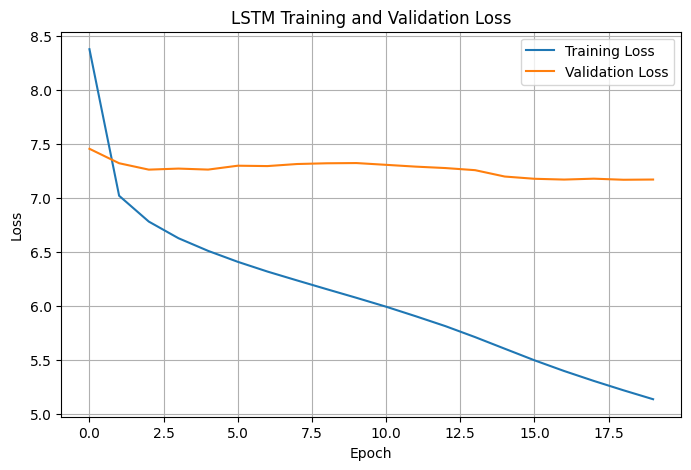

In [43]:

plt.figure(figsize=(8, 5))

plt.plot(
    lstm_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    lstm_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()


In [44]:

# Build Encoder Inference Model
encoder_model_lstm = Model(
    inputs=encoder_inputs_lstm,
    outputs=[hidden_state, cell_state]
)


In [45]:

# Build Decoder Inference Model
decoder_token_input_lstm = Input(shape=(1,))

decoder_hidden_input = Input(shape=(RNN_UNITS,))
decoder_cell_input = Input(shape=(RNN_UNITS,))

decoder_embedded_step_lstm = decoder_embedding_lstm(
    decoder_token_input_lstm
)

decoder_outputs_step_lstm, hidden_state_step, cell_state_step = decoder_lstm(
    decoder_embedded_step_lstm,
    initial_state=[decoder_hidden_input, decoder_cell_input]
)

decoder_probabilities_lstm = decoder_dense_lstm(
    decoder_outputs_step_lstm
)

decoder_model_lstm = Model(
    inputs=[
        decoder_token_input_lstm,
        decoder_hidden_input,
        decoder_cell_input
    ],
    outputs=[
        decoder_probabilities_lstm,
        hidden_state_step,
        cell_state_step
    ]
)


In [46]:

# Generate Headline using LSTM
def generate_lstm_headline(article_sequence):

    # Encode the article and get both states
    hidden_state, cell_state = encoder_model_lstm.predict(
        article_sequence.reshape(1, -1),
        verbose=0
    )

    # Start generation with SOS token
    current_token = np.array([
        [word_to_id[SOS_TOKEN]]
    ])

    generated_sequence = []

    for _ in range(MAX_TITLE_LEN - 1):

        # Predict the next word
        probabilities, hidden_state, cell_state = decoder_model_lstm.predict(
            [current_token, hidden_state, cell_state],
            verbose=0
        )

        next_token = int(
            np.argmax(probabilities[0, -1, :])
        )

        # Stop if EOS or PAD is generated
        if next_token == word_to_id[EOS_TOKEN]:
            break

        if next_token == word_to_id[PAD_TOKEN]:
            break

        generated_sequence.append(next_token)

        # Use predicted word as next input
        current_token = np.array([[next_token]])

    return sequence_to_text(generated_sequence)


In [47]:

sample_index = 0

sample_article = test_encoder_input[sample_index]

predicted_headline_lstm = generate_lstm_headline(sample_article)

print("Original Article:")
print(test["clean_article"].iloc[sample_index])

print("\nReference Headline:")
print(test["clean_title"].iloc[sample_index])

print("\nLSTM Predicted Headline:")
print(predicted_headline_lstm)


Original Article:
قال الكرملين اليوم الاربعاء انه يتعين رفع العقوبات المفروضة على روسيا حتى يتم تسليم الحبوب الروسية الى الاسواق الدولية. وافاد المتحدث باسم الكرملين دميتري بيسكوف في اتصال مع الصحفيين بانه لا توجد مناقشات فعلية جارية بشان رفع العقوبات.

Reference Headline:
الكرملين: يجب رفع العقوبات لتسليم الحبوب الروسية للاسواق

LSTM Predicted Headline:
ارتفاع الاسهم الامريكية من ارتفاع في الولايات المتحدة


In [48]:

for i in range(5):

    predicted_headline = generate_lstm_headline(
        test_encoder_input[i]
    )

    print("=" * 80)

    print("Article:")
    print(test["clean_article"].iloc[i])

    print("\nReference Headline:")
    print(test["clean_title"].iloc[i])

    print("\nLSTM Prediction:")
    print(predicted_headline)

    print("=" * 80)


Article:
قال الكرملين اليوم الاربعاء انه يتعين رفع العقوبات المفروضة على روسيا حتى يتم تسليم الحبوب الروسية الى الاسواق الدولية. وافاد المتحدث باسم الكرملين دميتري بيسكوف في اتصال مع الصحفيين بانه لا توجد مناقشات فعلية جارية بشان رفع العقوبات.

Reference Headline:
الكرملين: يجب رفع العقوبات لتسليم الحبوب الروسية للاسواق

LSTM Prediction:
ارتفاع الاسهم الامريكية من ارتفاع في الولايات المتحدة
Article:
وافق مجلس الشيوخ الامريكي اليوم على تمديد سقف الدين وتمويل الحكومة حتى الثامن من ديسمبر/كانون الاول المقبل. واقر المجلس ايضا مضاعفة حزمة المساعدات لضحايا الاعصار هارفي الى 15.25 مليار دولار مع اقتراب العاصفة ارما من فلوريدا. ويعود قرار مضاعفة حزمة المساعدات لضحايا الاعصار الى مجلس النواب للتصويت عليه، ووافق مجلس الشيوخ على الحزمة باغلبية كبيرة دون معارضة من اي عضو جمهوري.

Reference Headline:
مجلس الشيوخ الامريكي يقر حزمة مساعدات مضاعفة لضحايا "هارفي" وتمديد تمويل الحكومة

LSTM Prediction:
وكالة: الصين تعتزم ان اكبر النفط على امريكا على الصين
Article:
قالت وكالة فيتش ان تجنب الاغلاق الجزئي 

# Evaluation – BLEU-1 & ROUGE-L

In [40]:

!pip install -q rouge-score


In [51]:

from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

smooth = SmoothingFunction().method1

def calculate_lcs(tokens1, tokens2):
    m, n = len(tokens1), len(tokens2)

    dp = [[0] * (n + 1) for _ in range(m + 1)]

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if tokens1[i-1] == tokens2[j-1]:
                dp[i][j] = dp[i-1][j-1] + 1
            else:
                dp[i][j] = max(dp[i-1][j], dp[i][j-1])

    return dp[m][n]


def evaluate_model(model_function, test_articles, test_data):

    bleu_scores = []
    rouge_scores = []

    for i in range(len(test_articles)):

        reference = test_data["clean_title"].iloc[i]
        prediction = model_function(test_articles[i])

        reference_tokens = reference.split()
        prediction_tokens = prediction.split()

        # BLEU-1
        if prediction_tokens:
            bleu = sentence_bleu(
                [reference_tokens],
                prediction_tokens,
                weights=(1, 0, 0, 0),
                smoothing_function=smooth
            )
        else:
            bleu = 0.0

        # Arabic ROUGE-L
        if reference_tokens and prediction_tokens:

            lcs = calculate_lcs(
                reference_tokens,
                prediction_tokens
            )

            precision = lcs / len(prediction_tokens)
            recall = lcs / len(reference_tokens)

            rouge = (
                2 * precision * recall / (precision + recall)
                if precision + recall > 0 else 0.0
            )

        else:
            rouge = 0.0

        bleu_scores.append(bleu)
        rouge_scores.append(rouge)

    return np.mean(bleu_scores), np.mean(rouge_scores)


In [52]:

rnn_bleu, rnn_rouge = evaluate_model(
    generate_rnn_headline,
    test_encoder_input,
    test
)

print("SimpleRNN Results")
print("BLEU-1:", round(rnn_bleu, 4))
print("ROUGE-L:", round(rnn_rouge, 4))


SimpleRNN Results
BLEU-1: 0.0587
ROUGE-L: 0.0615


In [53]:

lstm_bleu, lstm_rouge = evaluate_model(
    generate_lstm_headline,
    test_encoder_input,
    test
)

print("LSTM Results")
print("BLEU-1:", round(lstm_bleu, 4))
print("ROUGE-L:", round(lstm_rouge, 4))


LSTM Results
BLEU-1: 0.0736
ROUGE-L: 0.0779


In [54]:

comparison = pd.DataFrame({
    "Model": ["SimpleRNN", "LSTM"],
    "BLEU-1": [rnn_bleu, lstm_bleu],
    "ROUGE-L": [rnn_rouge, lstm_rouge]
})

display(comparison)


,Model,BLEU-1,ROUGE-L
0,SimpleRNN,0.058661,0.061536
1,LSTM,0.073615,0.077876


In [55]:

results = []

for i in range(10):

    rnn_prediction = generate_rnn_headline(
        test_encoder_input[i]
    )

    lstm_prediction = generate_lstm_headline(
        test_encoder_input[i]
    )

    results.append({
        "Article": test["clean_article"].iloc[i],
        "Reference Headline": test["clean_title"].iloc[i],
        "SimpleRNN Prediction": rnn_prediction,
        "LSTM Prediction": lstm_prediction
    })

results_df = pd.DataFrame(results)

display(results_df)


,Article,Reference Headline,SimpleRNN Prediction,LSTM Prediction
0,قال الكرملين اليوم الاربعاء انه يتعين رفع العقوبات المفروضة على روسيا حتى يتم تسليم الحبوب الروسية الى الاسواق الدولية. وافاد المتحدث باسم الكرملين دميتري بيسكوف في اتصال مع الصحفيين بانه لا توجد مناقشات فعلية جارية بشان رفع العقوبات.,الكرملين: يجب رفع العقوبات لتسليم الحبوب الروسية للاسواق,تراجع الاسهم الامريكية في بداية الجلسة مع ارتفاع الاسهم,ارتفاع الاسهم الامريكية من ارتفاع في الولايات المتحدة
1,وافق مجلس الشيوخ الامريكي اليوم على تمديد سقف الدين وتمويل الحكومة حتى الثامن من ديسمبر/كانون الاول المقبل. واقر المجلس ايضا مضاعفة حزمة المساعدات لضحايا الاعصار هارفي الى 15.25 مليار دولار مع اقتراب العاصفة ارما من فلوريدا. ويعود قرار مضاعفة حزمة المساعدات لضحايا الاعصار الى مجلس النواب للتصويت عليه، ووافق مجلس الشيوخ على الحزمة باغلبية كبيرة دون معارضة من اي عضو جمهوري.,"مجلس الشيوخ الامريكي يقر حزمة مساعدات مضاعفة لضحايا ""هارفي"" وتمديد تمويل الحكومة",وكالة: الصين تعتزم رفع الفائدة جديدة في العالم,وكالة: الصين تعتزم ان اكبر النفط على امريكا على الصين
2,قالت وكالة فيتش ان تجنب الاغلاق الجزئي للحكومة الامريكية، لا يعني بالضرورة تحسن سياسات الموازنة، مشيرة الى توقعها ارتفاع العجز الحكومي نظرا لعدم القدرة على الاتفاق على تدابير مالية متوسطة الاجل، وانعدام الرغبة السياسية في ضبط الاوضاع المالية. واوضحت وكالة التصنيف الائتماني، ان احدث التوقعات تشير الى تجاوز عجز الحكومة العامة الامريكية نسبة 8% من الناتج المحلي الاجمالي سنويا في الفترة 2023-2025، وهو اعلى من التقديرات السابقة عند عجز نسبته 6.3% و6.6% و6.9% من الناتج المحلي الاجمالي خلال الاعوام. واضافت الوكالة في تقرير نشرته الاثنين على موقعها الرسمي، ان هذا يمثل تهديدات لمسار ديون الولايات المتحدة، حيث يساهم العجز المرتفع في زيادة نسبة الدين الحكومي العام لتتجاوز 120% من الناتج المحلي الاجمالي في عام 2025. وتفاقمت التحديات المالية بسبب ارتفاع اسعار الفائدة، وهو ما ابرزته الزيادة بنسبة 49% في صافي مدفوعات الفائدة على الدين العام خلال الربع الاخير من عام 2023 مقارنة بالعام السابق، وساهم ارتفاع تكاليف الاقتراض في تضاعف عجز الحكومة الفيدرالية الى ما يقدر بنحو 7.8% من الناتج المحلي الاجمالي. واصدر الكونجرس تشريعا لمواصلة تمويل الادارات الحكومية الفيدرالية عند المستويات الحالية في 18 يناير، وتم تاجيل المواعيد النهائية لتجنب الاغلاق الى 1 و8 مارس، بينما تستمر المحاولات للاتفاق على مشاريع قوانين المخصصات لهذه السنة المالية، والتي بدات في اكتوبر.,فيتش تتوقع اتساع عجز الموازنة الامريكية رغم تجنب اغلاق الحكومة,"وزير بي بي سي"" في امريكا من النفط على ارتفاع",ارتفاع الاسهم الامريكية مع ارتفاع في ارتفاع في الولايات المتحدة خلال التوالي
3,رفضت محكمة فيدرالية امريكية دعوى قضائية تتهم شركة روبن هود ماركتس Robinhood Markets بانتهاك القانون من خلال تقييد التداولات على ما يسمى اسهم الميم خلال يناير 2021. واقرت سيسيليا التوناجا كبير قضاة المحكمة الفيدرالية في ميامي رفض الدعوى المقامة ضد روبن هود، مستشهدة باتفاقية الشركة مع العملاء، والتي تسمح لها بتقييد التداول. وردا على القرار، صرحت ناتاليا سالاس محامية المدعين، بانهم يخططون لاستئناف القرار نيابة عن المستثمرين غير الملتزمين باتفاقية روبن هود مع العملاء. وكانت تلك الدعوى جزءا من موجة الدعاوى القضائية التي تعرضت لها روبن هود بعدما منعت العملاء من شراء بعض الاسهم، والمعروفة باسم اسهم الميم، وهي اسهم الشركات التي لاقت اقبالا من صغار المستثمرين وتتسم بتقلبات سعرية مرتفعة بين مجتمعات الانترنت، بما في ذلك اسهم جيم ستوب GameStop وايه ام سي AMC. وتهدف تلك الدعوى الى حصول المدعين على تعويضات من شركة روبن هود، بعد الخسائر التي تقدر بالمليارات بسبب تقييد التداول.,"محكمة امريكية ترفض دعوى ضد ""روبن هود"" حول تقييد تداول اسهم ""الميم""",وكالة: الصين تعتزم رفع الفائدة جديدة في العالم,وكالة: الصين تعتزم ان اكبر النفط على امريكا مع الصين
4,اصدر الملياردير الامريكي الشهير بيل جيتس وزوجته مليندا خطابهما السنوي لعام 2016 والذي شاركا من خلاله اهم امنياتهما حيث تمنت مليندا امتلاك المزيد من الوقت، بينما تمنى جيتس المزيد من الطاقة خاصة الرخيصة والنظيفة لمساعدة الاسر الفقيرة حول العالم دون التسبب في تغيرات مناخية. واوضح جيتس ان جزءا من حل ازمة التغيرات المناخية يكمن في استثمار المزيد من الاموال في الطاقة النظيفة والابحاث المتعلقة بها والمزيد من الابتكارات لتحسين قدرة العالم على تخزين الطاقة بشكل ارخص واكثر فا